<a href="https://colab.research.google.com/github/xenny0707/Twitter_Sentiment_Analysis/blob/main/Twitter_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 Twitter Sentiment Analysis using NLP & Machine Learning
**Dataset:** Sentiment140 (1.6 million tweets) | **Model:** TF-IDF + Logistic Regression | **Platform:** Google Colab

**How to run:** `Runtime → Run all` (or run cells top to bottom). No API keys or paid services needed.

| Cell | Purpose |
|------|---------|
| 1 | Environment setup |
| 2 | Download & load dataset |
| 3 | Exploratory data analysis |
| 4 | Text preprocessing |
| 5 | TF-IDF feature extraction (explained) |
| 6 | Train-test split + vectorizing |
| 7 | Model training |
| 8 | Evaluation |
| 9 | Visualizations (top words, word clouds) |
| 10 | Live prediction on new text |
| 11 | Save model + viva cheat-sheet |

## Cell 1: Environment Setup

In [ ]:
# ===== CELL 1: ENVIRONMENT SETUP =====
import sys, subprocess, importlib

# Install any library that is missing (Colab already has most of them)
REQUIRED = {"pandas": "pandas", "numpy": "numpy", "nltk": "nltk", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "seaborn": "seaborn", "wordcloud": "wordcloud",
            "requests": "requests", "joblib": "joblib", "pyarrow": "pyarrow"}
for module, pip_name in REQUIRED.items():
    try:
        importlib.import_module(module)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import os, re, time, html, warnings, zipfile, io
import numpy as np
import pandas as pd
import requests
import joblib
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_colwidth", 90)

# NLTK resources (stopwords). If the download is blocked we fall back to a built-in list later.
try:
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    stopwords.words("english")
    NLTK_OK = True
except Exception as e:
    print("⚠️ Could not load NLTK stopwords, a built-in list will be used instead:", e)
    NLTK_OK = False

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("✅ Environment ready")
print(f"   Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | NLTK {nltk.__version__}")
print(f"   Running in Google Colab: {IN_COLAB}")

✅ Environment ready
   Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | NLTK 3.9.1
   Running in Google Colab: True


## Cell 2: Dataset Download and Loading
Sentiment140 labels: `0 = Negative`, `4 = Positive` (there are no neutral tweets in the training file).
Change `SAMPLE_SIZE` below. Use `None` for the full 1.6 million tweets (slower, needs more RAM).

In [ ]:
# ===== CELL 2: DOWNLOAD & LOAD DATASET =====
SAMPLE_SIZE = 200_000      # 👈 set to None to use the FULL 1.6M tweets
RANDOM_STATE = 42

DATA_DIR = "sentiment140_data"
os.makedirs(DATA_DIR, exist_ok=True)
CSV_PATH = os.path.join(DATA_DIR, "training.1600000.processed.noemoticon.csv")
COLS = ["target", "ids", "date", "flag", "user", "text"]

# Public sources are tried in order until one works
SOURCES = [
    ("zip",     "https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip"),
    ("zip",     "http://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip"),
    ("parquet", "https://huggingface.co/datasets/stanfordnlp/sentiment140/resolve/refs%2Fconvert%2Fparquet/sentiment140/train/0000.parquet"),
]

def download_file(url, timeout=120):
    """Download a URL into memory with a simple progress message. Returns bytes or None."""
    try:
        r = requests.get(url, stream=True, timeout=timeout)
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        buf, done = io.BytesIO(), 0
        for chunk in r.iter_content(chunk_size=1 << 20):
            buf.write(chunk); done += len(chunk)
            if total:
                print(f"\r   downloaded {done/1e6:6.1f} / {total/1e6:.1f} MB", end="")
        print()
        return buf.getvalue()
    except Exception as e:
        print(f"   ✗ failed: {type(e).__name__}: {str(e)[:100]}")
        return None

def make_demo_dataset(n=6000, seed=RANDOM_STATE):
    """LAST-RESORT offline dataset so the notebook never crashes. Not real Twitter data!"""
    rng = np.random.default_rng(seed)
    pos = ["i love this", "what a great day", "so happy right now", "this is amazing", "best movie ever",
           "thanks so much, awesome", "feeling fantastic today", "not bad at all, really good", "loving my new phone",
           "can not wait for the weekend, so excited"]
    neg = ["i hate this", "what a terrible day", "so sad right now", "this is awful", "worst movie ever",
           "so tired and annoyed", "feeling horrible today", "not good at all, really bad", "my phone is broken again",
           "never going back there, so disappointing"]
    extra = ["lol", "friends", "monday", "work", "home", "tonight", "school", "music", "coffee", "bus"]
    rows = []
    for _ in range(n):
        lab = int(rng.integers(0, 2))
        base = rng.choice(pos if lab else neg)
        rows.append((4 if lab else 0, f"@user {base} {rng.choice(extra)} #{rng.choice(extra)} http://t.co/x"))
    return pd.DataFrame(rows, columns=["target", "text"])

def load_raw_dataset():
    # 1) already downloaded earlier in this session
    if os.path.exists(CSV_PATH):
        print("📂 Found existing CSV, loading it ...")
        return pd.read_csv(CSV_PATH, encoding="latin-1", header=None, names=COLS), "Sentiment140 (cached)"

    # 2) try each public source
    for kind, url in SOURCES:
        print(f"⬇️  Trying: {url}")
        data = download_file(url)
        if data is None:
            continue
        try:
            if kind == "zip":
                with zipfile.ZipFile(io.BytesIO(data)) as z:
                    name = [n for n in z.namelist() if "training" in n and n.endswith(".csv")][0]
                    with z.open(name) as f, open(CSV_PATH, "wb") as out:
                        out.write(f.read())
                return pd.read_csv(CSV_PATH, encoding="latin-1", header=None, names=COLS), "Sentiment140 (Stanford)"
            else:
                df = pd.read_parquet(io.BytesIO(data))
                df = df.rename(columns={"sentiment": "target"})
                return df, "Sentiment140 (Hugging Face mirror)"
        except Exception as e:
            print(f"   ✗ downloaded but could not be read: {e}")

    # 3) manual upload (only possible in Colab)
    if IN_COLAB:
        print("\n⚠️ All downloads failed. Upload 'training.1600000.processed.noemoticon.csv' "
              "(from Kaggle/Stanford) now, or cancel to use the tiny demo dataset.")
        try:
            from google.colab import files
            up = files.upload()
            if up:
                name = list(up.keys())[0]
                return pd.read_csv(name, encoding="latin-1", header=None, names=COLS), "Sentiment140 (uploaded)"
        except Exception as e:
            print("   Upload skipped:", e)

    # 4) offline demo data
    print("\n🚨 USING A SMALL SYNTHETIC DEMO DATASET (NOT real tweets). Re-run with internet or upload the CSV.")
    return make_demo_dataset(), "SYNTHETIC DEMO DATA"

raw, DATA_SOURCE = load_raw_dataset()

# ---- Validation ----
assert len(raw) > 0, "Dataset is empty"
assert {"target", "text"}.issubset(raw.columns), "Missing 'target'/'text' columns"
assert set(raw["target"].unique()).issubset({0, 4}), f"Unexpected labels: {raw['target'].unique()}"
print(f"\n✅ Loaded {len(raw):,} rows from: {DATA_SOURCE}")

# ---- Optional stratified sampling (keeps 50/50 balance) ----
if SAMPLE_SIZE and len(raw) > SAMPLE_SIZE:
    df = (raw.groupby("target", group_keys=False)
             .apply(lambda g: g.sample(SAMPLE_SIZE // 2, random_state=RANDOM_STATE))
             .sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True))
    print(f"✂️  Using a balanced sample of {len(df):,} tweets (SAMPLE_SIZE={SAMPLE_SIZE:,})")
else:
    df = raw.copy()
    print(f"Using all {len(df):,} tweets")

# ---- Map labels: 0 -> Negative, 4 -> Positive ----
df["sentiment"] = df["target"].map({0: "Negative", 4: "Positive"})
df["label"] = (df["target"] == 4).astype(int)       # model uses 0 / 1
del raw
df[["text", "sentiment", "label"]].head()

⬇️  Trying: https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip
   downloaded   81.4 / 81.4 MB

✅ Loaded 1,600,000 rows from: Sentiment140 (Stanford)
✂️  Using a balanced sample of 200,000 tweets (SAMPLE_SIZE=200,000)


,text,sentiment,label
0,Looks like the sun finally located Trondheim ;-) hope summer's on it's way,Positive,1
1,A long weekend begins. The sun is shining and I'm happy ! Exams soon,Negative,0
2,to the beach we go! hope it stays nice...,Positive,1
3,@JBFutureboy I missed it busted need to do a reunion tour. That would make my year. N...,Negative,0
4,Why I can't change my background image??,Negative,0


## Cell 3: Exploratory Data Analysis (EDA)

Shape (rows, columns): (200000, 8)
Columns: ['target', 'ids', 'date', 'flag', 'user', 'text', 'sentiment', 'label']

Missing values per column:
 target       0
ids          0
date         0
flag         0
user         0
text         0
sentiment    0
label        0
dtype: int64

Duplicate rows (identical tweet text): 886 (0.44%)

Sample records:


,sentiment,text
49673,Positive,@evablue my favourite #iheartslitmywristsmusic musician. â« http://blip.fm/~7t27w
171551,Negative,@pittsburghmark yeah damn
5506,Positive,"trying out twitter, and seeing what it's all about"
38370,Negative,i wanna go home
36930,Negative,"@lankydutch Yes, and I'm on their side, but it's hot and my bin was getting really sti..."
167783,Positive,"Believe in yourself and all things are possible! #quotes ...now its official, goodnight"
67487,Positive,@iheartpluto was sein muss muss sein.
101486,Positive,"All in 1 service, but times 2!!! @siondenhaag it's definately happening - see ya there..."


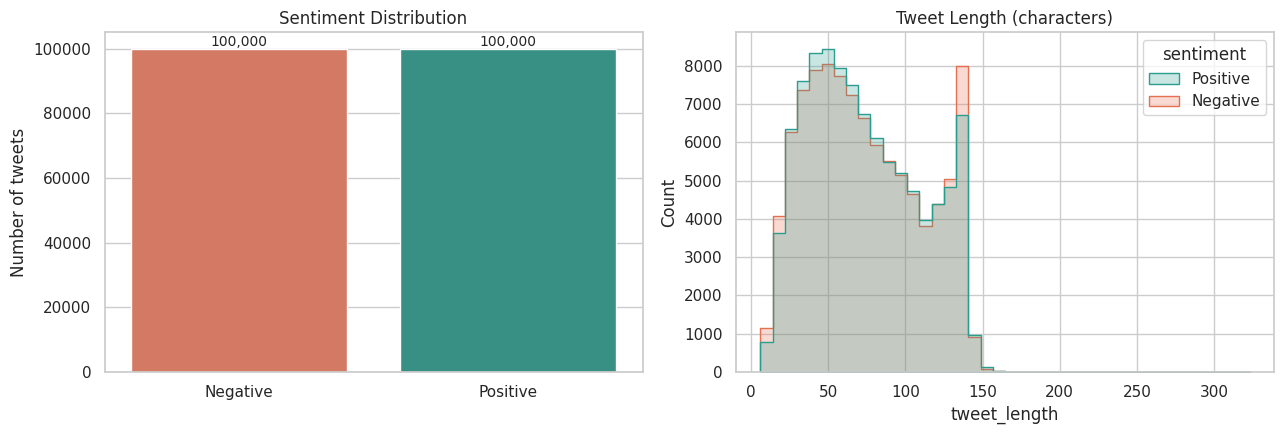

📝 OBSERVATIONS (in simple words):
  • The dataset has 200,000 tweets. Negative: 100,000, Positive: 100,000.
  • Classes are (almost) perfectly balanced, so plain accuracy is a fair metric.
  • Average tweet length is 74 characters (Twitter's old limit was 140).
  • Tweets contain noise: links, @usernames, #hashtags, slang, repeated letters. We clean them next.


In [ ]:
# ===== CELL 3: EDA =====
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values per column:\n", df.isnull().sum())
dup_text = df["text"].duplicated().sum()
print(f"\nDuplicate rows (identical tweet text): {dup_text:,} ({dup_text/len(df):.2%})")

print("\nSample records:")
display(df[["sentiment", "text"]].sample(8, random_state=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df["sentiment"].value_counts()
sns.countplot(data=df, x="sentiment", order=["Negative", "Positive"],
              palette={"Negative": "#e76f51", "Positive": "#2a9d8f"}, ax=axes[0])
axes[0].set_title("Sentiment Distribution"); axes[0].set_xlabel(""); axes[0].set_ylabel("Number of tweets")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=10)

df["tweet_length"] = df["text"].str.len()
sns.histplot(data=df, x="tweet_length", hue="sentiment", bins=40, element="step",
             palette={"Negative": "#e76f51", "Positive": "#2a9d8f"}, ax=axes[1])
axes[1].set_title("Tweet Length (characters)")
plt.tight_layout(); plt.show()

print("📝 OBSERVATIONS (in simple words):")
print(f"  • The dataset has {len(df):,} tweets. Negative: {counts.get('Negative',0):,}, Positive: {counts.get('Positive',0):,}.")
print("  • Classes are (almost) perfectly balanced, so plain accuracy is a fair metric.")
print(f"  • Average tweet length is {df['tweet_length'].mean():.0f} characters (Twitter's old limit was 140).")
print("  • Tweets contain noise: links, @usernames, #hashtags, slang, repeated letters. We clean them next.")

## Cell 4: Text Preprocessing
Steps: lowercase → decode HTML → remove URLs & @usernames → keep hashtag words → expand contractions →
keep letters only → shorten stretched words (`soooo`→`soo`) → remove stopwords **except negations** (`not`, `never`, `no` …).

> **Why keep negations?** "good" and "not good" mean opposite things. Removing "not" would destroy the sentiment.

In [ ]:
# ===== CELL 4: TEXT PREPROCESSING =====
# --- stopwords but KEEP negation words ---
NEGATIONS = {"no", "nor", "not", "never", "none", "neither", "nobody", "nothing", "nowhere", "cannot"}
FALLBACK_STOPWORDS = set("""a about above after again against all am an and any are as at be because been before being below
between both but by can did do does doing down during each few for from further had has have having he her here hers herself
him himself his how i if in into is it its itself just me more most my myself of off on once only or other our ours ourselves
out over own same she should so some such than that the their theirs them themselves then there these they this those through
to too under until up very was we were what when where which while who whom why will with you your yours yourself yourselves""".split())
BASE_STOPWORDS = set(stopwords.words("english")) if NLTK_OK else FALLBACK_STOPWORDS
STOP_WORDS = BASE_STOPWORDS - NEGATIONS

# --- contractions ---
CONTRACTIONS = {"won't": "will not", "can't": "can not", "cannot": "can not", "n't": " not", "'re": " are", "'m": " am",
                "'ll": " will", "'ve": " have", "'d": " would", "'s": " is"}
APOSTROPHE_LESS = {"dont": "do not", "doesnt": "does not", "didnt": "did not", "cant": "can not", "wont": "will not",
                   "isnt": "is not", "arent": "are not", "wasnt": "was not", "werent": "were not", "couldnt": "could not",
                   "wouldnt": "would not", "shouldnt": "should not", "havent": "have not", "hasnt": "has not",
                   "im": "i am", "ive": "i have"}

# compiled regexes (faster on 200k+ tweets)
RE_URL      = re.compile(r"(https?://\S+|www\.\S+)")
RE_MENTION  = re.compile(r"@\w+")
RE_HASHTAG  = re.compile(r"#(\w+)")
RE_NONALPHA = re.compile(r"[^a-z\s]")
RE_REPEAT   = re.compile(r"(.)\1{2,}")      # 3+ repeated letters -> 2
RE_SPACES   = re.compile(r"\s+")

def clean_tweet(text):
    """ONE function used for training AND live prediction -> guarantees consistency."""
    text = html.unescape(str(text)).lower().replace("’", "'")
    text = RE_URL.sub(" ", text)
    text = RE_MENTION.sub(" ", text)
    text = RE_HASHTAG.sub(r" \1 ", text)               # '#happy' -> 'happy'
    text = text.replace("won't", "will not").replace("can't", "can not").replace("cannot", "can not")
    for short, full in CONTRACTIONS.items():
        text = text.replace(short, full)
    text = RE_NONALPHA.sub(" ", text)
    text = RE_REPEAT.sub(r"\1\1", text)
    tokens = []
    for tok in text.split():
        tokens.extend(APOSTROPHE_LESS.get(tok, tok).split())
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    return RE_SPACES.sub(" ", " ".join(tokens)).strip()

# quick unit tests
assert "not" in clean_tweet("I don't like this").split()
assert "never" in clean_tweet("I will never go back").split()
assert "http" not in clean_tweet("check this http://t.co/abc @bob")
print("✅ Preprocessing sanity checks passed\n")

t0 = time.time()
df["clean_text"] = df["text"].apply(clean_tweet)
print(f"Cleaned {len(df):,} tweets in {time.time()-t0:.1f}s")

before = len(df)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)      # remove empty/unusable rows
print(f"Removed {before - len(df):,} empty tweets after cleaning -> {len(df):,} remain")

print("\nOriginal vs Cleaned:")
display(df[["text", "clean_text"]].sample(8, random_state=3))

✅ Preprocessing sanity checks passed

Cleaned 200,000 tweets in 7.8s
Removed 974 empty tweets after cleaning -> 199,026 remain

Original vs Cleaned:


,text,clean_text
147449,eating menudo. my favorite! yum-yum.,eating menudo favorite yum yum
65536,At work $$... I think I'm getting strep throat,work think getting strep throat
146231,Faithyhopes flatmates room was broken into last night and I obv slept better than I im...,faithyhopes flatmates room broken last night obv slept better imagined never heard thing
166929,"regents tomorrow, well today",regents tomorrow well today
39706,"@viltsukas It's not cute, but thanks for the compliment! Well I hate them, they're ru...",not cute thanks compliment well hate ruining life know
38456,panasonic toughbook lid damaged within one year and a half. Thought it was built to wi...,panasonic toughbook lid damaged within one year half thought built withstand dragged s...
127599,$750 for rent minus $850 for my car minus whatever i spend in san francisco this weeke...,rent minus car minus whatever spend san francisco weekend broke
183964,"this yea will be the worst birthday ever, i have 3 exams on it and i have to wake up a...",yea worst birthday ever exams wake come home happy bday


## Cell 5: Feature Extraction with TF-IDF
Computers can't read words, so we turn each tweet into a vector of numbers.

**TF-IDF = Term Frequency × Inverse Document Frequency**
- **TF**: how often a word appears in *this* tweet.
- **IDF**: `log(total tweets / tweets containing the word)`. Rare words get a *higher* weight, super-common words (like "get") get a *lower* weight.
- **Unigrams + bigrams** (`ngram_range=(1,2)`): single words *and* pairs such as "not good", which captures negation.
- **No data leakage:** the vectorizer learns its vocabulary and IDF values from the **training set only** (done in Cell 6).

In [ ]:
# ===== CELL 5: TF-IDF SETUP + SMALL DEMO =====
# Tiny example so you can SEE how TF-IDF works (this vectorizer is only for the demo)
toy = ["love this movie", "hate this movie", "not good movie"]
toy_vec = TfidfVectorizer(ngram_range=(1, 2))
toy_matrix = toy_vec.fit_transform(toy)
print("Toy TF-IDF matrix (rows = tweets, columns = words/bigrams):")
display(pd.DataFrame(toy_matrix.toarray(), columns=toy_vec.get_feature_names_out(), index=toy).round(2))
print("👉 'movie' appears in every tweet, so its weight is low. 'love'/'hate' are rare, so their weights are higher.\n")

# The REAL vectorizer used in the project
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),     # unigrams + bigrams
    max_features=100_000,   # cap vocabulary -> controls memory
    min_df=3,               # ignore words seen in fewer than 3 tweets (typos/noise)
    max_df=0.9,             # ignore words in >90% of tweets
    sublinear_tf=True,      # use 1+log(tf) to dampen very frequent words
    dtype=np.float32,       # half the memory of float64
)
print("TF-IDF configured (it will be fitted on the training data in the next cell).")

Toy TF-IDF matrix (rows = tweets, columns = words/bigrams):


,good,good movie,hate,hate this,love,love this,movie,not,not good,this,this movie
love this movie,0.00,0.00,0.00,0.00,0.53,0.53,0.32,0.00,0.00,0.41,0.41
hate this movie,0.00,0.00,0.53,0.53,0.00,0.00,0.32,0.00,0.00,0.41,0.41
not good movie,0.48,0.48,0.00,0.00,0.00,0.00,0.28,0.48,0.48,0.00,0.00


👉 'movie' appears in every tweet, so its weight is low. 'love'/'hate' are rare, so their weights are higher.

TF-IDF configured (it will be fitted on the training data in the next cell).


## Cell 6: Train-Test Split (80:20) and Vectorization

In [ ]:
# ===== CELL 6: TRAIN-TEST SPLIT + FIT TF-IDF ON TRAIN ONLY =====
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.20,
    stratify=df["label"],        # same Positive/Negative ratio in both sets
    random_state=RANDOM_STATE,   # reproducible results
)
print(f"Training tweets: {len(X_train_text):,} | Testing tweets: {len(X_test_text):,}")
print("Train class balance:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test  class balance:", y_test.value_counts(normalize=True).round(3).to_dict())

t0 = time.time()
X_train = tfidf.fit_transform(X_train_text)     # learn vocabulary + IDF from TRAIN only
X_test  = tfidf.transform(X_test_text)          # only apply to TEST (no leakage)
print(f"\nTF-IDF done in {time.time()-t0:.1f}s")
print(f"Vocabulary size: {len(tfidf.vocabulary_):,} features")
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Sparsity: {1 - X_train.nnz / (X_train.shape[0]*X_train.shape[1]):.2%} of the matrix is zeros (stored efficiently as a sparse matrix)")

Training tweets: 159,220 | Testing tweets: 39,806
Train class balance: {0: 0.5, 1: 0.5}
Test  class balance: {0: 0.5, 1: 0.5}

TF-IDF done in 8.8s
Vocabulary size: 62,994 features
X_train shape: (159220, 62994) | X_test shape: (39806, 62994)
Sparsity: 99.99% of the matrix is zeros (stored efficiently as a sparse matrix)


## Cell 7: Model Training: Logistic Regression
Logistic Regression learns a weight for every word/bigram. It adds up the weights of the words in a tweet and passes the total through the
**sigmoid function** to get a probability between 0 and 1. If P(positive) > 0.5 → Positive, else Negative.

In [ ]:
# ===== CELL 7: TRAIN LOGISTIC REGRESSION =====
model = LogisticRegression(
    C=1.0,               # regularization strength (smaller = stronger regularization)
    solver="liblinear",  # fast and reliable for large sparse binary problems
    max_iter=1000,
    random_state=RANDOM_STATE,
)
print("⏳ Training Logistic Regression ...")
t0 = time.time()
model.fit(X_train, y_train)
print(f"✅ Training completed in {time.time()-t0:.1f} seconds")
print(f"   Number of learned weights: {model.coef_.shape[1]:,}")

⏳ Training Logistic Regression ...
✅ Training completed in 2.0 seconds
   Number of learned weights: 62,994


## Cell 8: Model Evaluation

Training accuracy: 0.8416
Testing  accuracy: 0.7920
Precision: 0.7859 | Recall: 0.8023 | F1: 0.7940 | ROC-AUC: 0.8716
Gap between train and test accuracy: 0.0495 (small gap = no serious overfitting)

              precision    recall  f1-score   support

    Negative     0.7984    0.7818    0.7900     19918
    Positive     0.7859    0.8023    0.7940     19888

    accuracy                         0.7920     39806
   macro avg     0.7922    0.7920    0.7920     39806
weighted avg     0.7922    0.7920    0.7920     39806



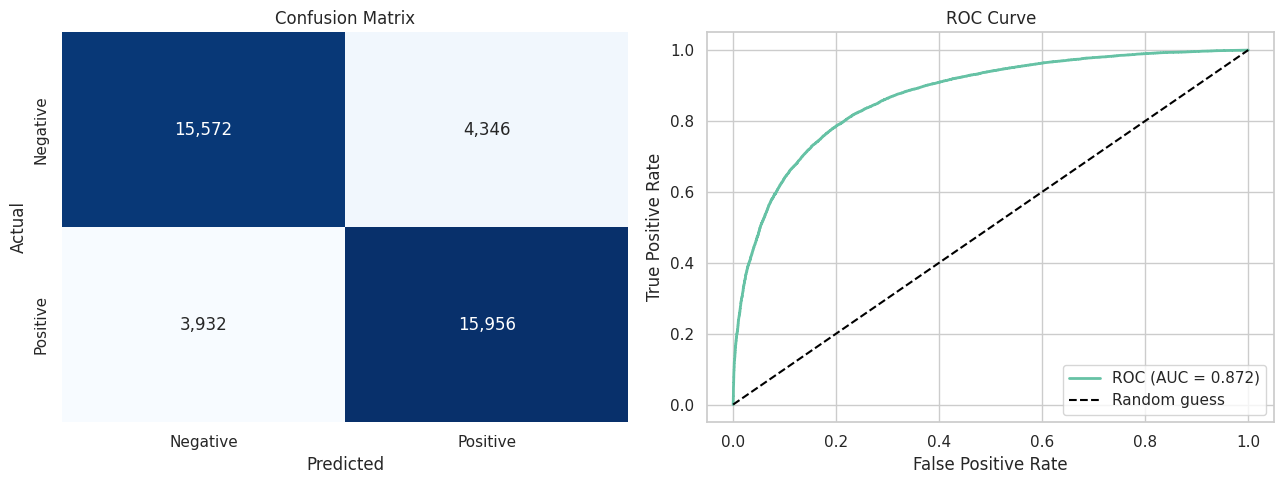

Reading the matrix: 15,956 positive tweets correctly found, 15,572 negative correctly found, 4,346 negatives wrongly called positive, 3,932 positives wrongly called negative.


In [ ]:
# ===== CELL 8: EVALUATION =====
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc  = accuracy_score(y_test, y_pred)
print(f"Training accuracy: {train_acc:.4f}")
print(f"Testing  accuracy: {test_acc:.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f} | Recall: {recall_score(y_test, y_pred):.4f} | "
      f"F1: {f1_score(y_test, y_pred):.4f} | ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Gap between train and test accuracy: {train_acc - test_acc:.4f} (small gap = no serious overfitting)\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_title("Confusion Matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, lw=2, label=f"ROC (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curve"); axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Reading the matrix: {tp:,} positive tweets correctly found, {tn:,} negative correctly found, "
      f"{fp:,} negatives wrongly called positive, {fn:,} positives wrongly called negative.")
if DATA_SOURCE.startswith("SYNTHETIC"):
    print("\n⚠️ These scores come from SYNTHETIC demo data and are unrealistically high. "
          "On real Sentiment140 expect roughly 77-80% accuracy.")

## Cell 9: Visualizations: Most Influential Words, Word Clouds, Error Analysis

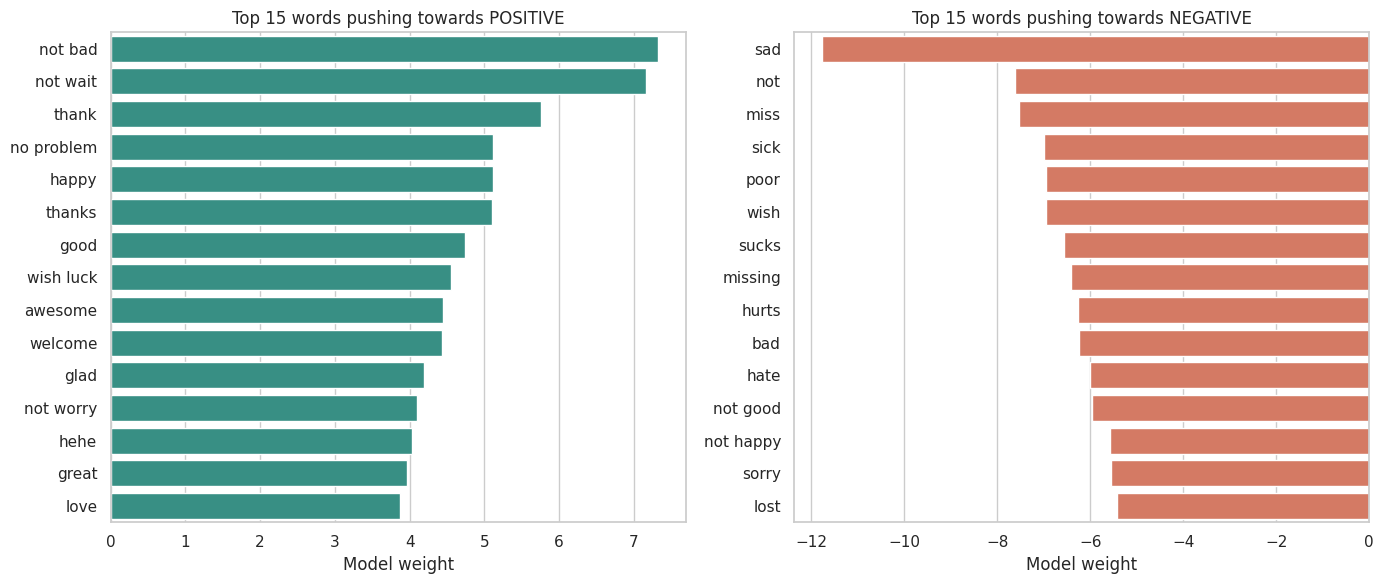

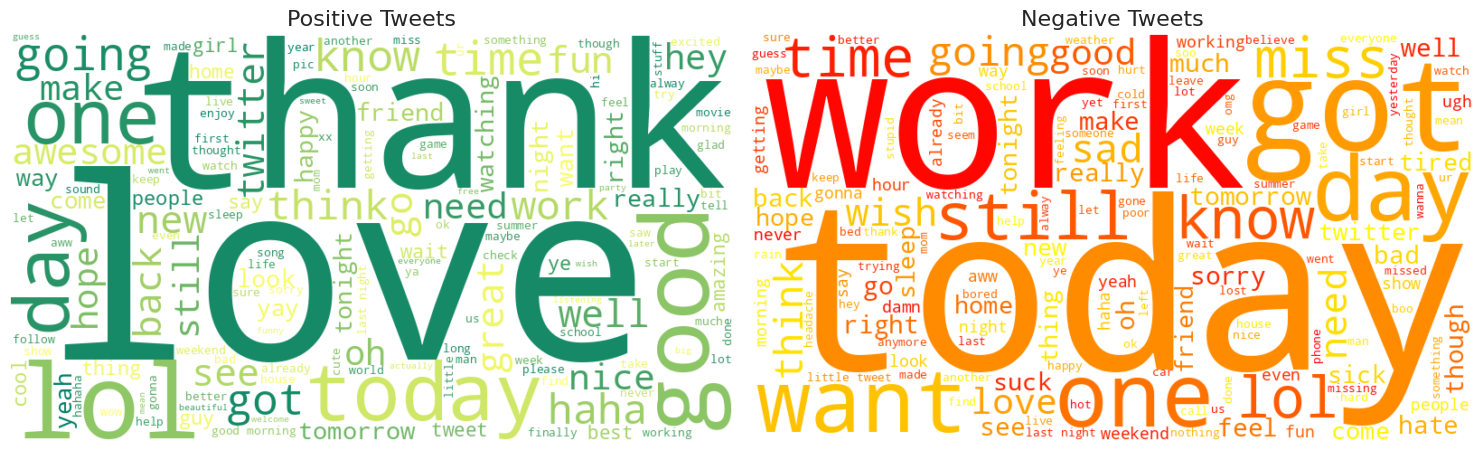

Examples where the model was confidently WRONG (sarcasm, missing context and noisy labels are common causes):


,clean_text,actual,predicted,confidence
39351,not,Positive,Negative,0.999
1559,not,Positive,Negative,0.999
27826,not ruh tard,Positive,Negative,0.999
29264,not,Positive,Negative,0.999
36171,not,Positive,Negative,0.999
1272,not disobeying,Positive,Negative,0.999
7121,wish,Positive,Negative,0.998
8110,eyeballs thank,Negative,Positive,0.998


In [ ]:
# ===== CELL 9: TOP WORDS + WORD CLOUDS + ERRORS =====
feature_names = np.array(tfidf.get_feature_names_out())
coefs = model.coef_[0]
top_n = 15
top_pos_idx = np.argsort(coefs)[-top_n:][::-1]
top_neg_idx = np.argsort(coefs)[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=coefs[top_pos_idx], y=feature_names[top_pos_idx], color="#2a9d8f", ax=axes[0])
axes[0].set_title(f"Top {top_n} words pushing towards POSITIVE"); axes[0].set_xlabel("Model weight")
sns.barplot(x=coefs[top_neg_idx], y=feature_names[top_neg_idx], color="#e76f51", ax=axes[1])
axes[1].set_title(f"Top {top_n} words pushing towards NEGATIVE"); axes[1].set_xlabel("Model weight")
plt.tight_layout(); plt.show()

# Word clouds (use up to 50k tweets per class to stay fast)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, colormap) in zip(axes, [("Positive", "summer"), ("Negative", "autumn")]):
    subset = df.loc[df["sentiment"] == name, "clean_text"]
    text = " ".join(subset.sample(min(50_000, len(subset)), random_state=RANDOM_STATE))
    wc = WordCloud(width=800, height=450, background_color="white", colormap=colormap,
                   max_words=150, random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{name} Tweets", fontsize=16)
plt.tight_layout(); plt.show()

# Error analysis: look at tweets the model got wrong
test_view = pd.DataFrame({"clean_text": X_test_text.values, "actual": y_test.values, "predicted": y_pred,
                          "confidence": np.where(y_pred == 1, y_proba, 1 - y_proba)})
wrong = test_view[test_view["actual"] != test_view["predicted"]].sort_values("confidence", ascending=False)
wrong["actual"] = wrong["actual"].map({0: "Negative", 1: "Positive"})
wrong["predicted"] = wrong["predicted"].map({0: "Negative", 1: "Positive"})
print("Examples where the model was confidently WRONG (sarcasm, missing context and noisy labels are common causes):")
display(wrong.head(8).round(3))

## Cell 10: Live Prediction on New Text

In [ ]:
# ===== CELL 10: LIVE PREDICTION =====
def predict_sentiment(text):
    """Takes ANY raw text, applies the SAME cleaning + fitted TF-IDF + trained model."""
    cleaned = clean_tweet(text)
    if not cleaned:
        return {"text": text, "sentiment": "Unknown (no usable words)", "confidence": None, "cleaned": cleaned}
    vec = tfidf.transform([cleaned])
    p_pos = model.predict_proba(vec)[0, 1]
    label = "Positive 😊" if p_pos >= 0.5 else "Negative 😞"
    return {"text": text, "sentiment": label, "confidence": max(p_pos, 1 - p_pos), "cleaned": cleaned}

examples = [
    "I absolutely love this new phone, the camera is amazing!",
    "Worst service ever. I will never come back to this place.",
    "The movie was not good at all",
    "Can't wait for the weekend!!! #excited",
    "I don't hate it, it's actually pretty great",
    "Missing my friends so much today :(",
]
rows = [predict_sentiment(t) for t in examples]
out = pd.DataFrame(rows)
out["confidence"] = out["confidence"].map(lambda c: f"{c:.1%}" if c is not None else "-")
display(out[["text", "sentiment", "confidence"]])

# Optional: type your own text during the demo (type 'quit' to stop)
INTERACTIVE = True
if INTERACTIVE:
    try:
        while True:
            user_text = input("\n✍️  Enter a tweet/sentence (or 'quit'): ").strip()
            if user_text.lower() in {"quit", "exit", "q", ""}:
                break
            r = predict_sentiment(user_text)
            conf = f"{r['confidence']:.1%}" if r["confidence"] is not None else "-"
            print(f"   → {r['sentiment']}  (confidence {conf})   [cleaned: '{r['cleaned']}']")
    except (EOFError, KeyboardInterrupt):
        pass

,text,sentiment,confidence
0,"I absolutely love this new phone, the camera is amazing!",Positive 😊,91.9%
1,Worst service ever. I will never come back to this place.,Negative 😞,90.6%
2,The movie was not good at all,Negative 😞,89.4%
3,Can't wait for the weekend!!! #excited,Positive 😊,95.6%
4,"I don't hate it, it's actually pretty great",Positive 😊,65.2%
5,Missing my friends so much today :(,Negative 😞,88.9%


## Cell 11: Save the Model + Project Summary

In [ ]:
# ===== CELL 11: SAVE MODEL =====
joblib.dump(model, "sentiment_model.joblib")
joblib.dump(tfidf, "tfidf_vectorizer.joblib")
print("💾 Saved: sentiment_model.joblib, tfidf_vectorizer.joblib")
print("   To reuse later:  model = joblib.load('sentiment_model.joblib');  tfidf = joblib.load('tfidf_vectorizer.joblib')")

if IN_COLAB:
    try:
        from google.colab import files
        files.download("sentiment_model.joblib"); files.download("tfidf_vectorizer.joblib")
    except Exception as e:
        print("Download skipped:", e)

print("\n" + "="*60)
print("PROJECT SUMMARY")
print("="*60)
print(f"Data source      : {DATA_SOURCE}")
print(f"Tweets used      : {len(df):,}")
print(f"Features         : TF-IDF unigrams+bigrams, {len(tfidf.vocabulary_):,} features")
print(f"Model            : Logistic Regression")
print(f"Test accuracy    : {test_acc:.2%}")

## 🎓 Viva Cheat-Sheet

**Q1. What is sentiment analysis?** Automatically deciding whether a piece of text expresses a positive or negative opinion.

**Q2. Why Sentiment140?** It's a public dataset of 1.6M tweets, labelled automatically from emoticons (🙂 = positive, 🙁 = negative). Labels are therefore a little noisy, which is why ~78% is a good score.

**Q3. Why remove stopwords but keep "not"?** Stopwords carry little meaning; negations flip meaning ("good" vs "not good").

**Q4. What is TF-IDF?** A weight for each word = how frequent it is in a tweet × how rare it is across all tweets.

**Q5. Why bigrams?** They capture short phrases like "not good" or "so happy" that single words miss.

**Q6. What is data leakage and how did you avoid it?** Using test-set information during training. We fit TF-IDF **only** on the training split, then just transformed the test split.

**Q7. Why Logistic Regression?** Fast, works very well on sparse text features, gives probabilities, and its weights are interpretable (we plotted them).

**Q8. Why stratified split?** To keep the same class ratio in train and test.

**Q9. What are precision, recall, F1?** Precision = of predicted positives, how many are right. Recall = of real positives, how many we found. F1 = harmonic mean of both.

**Q10. Limitations?** Sarcasm, slang, no neutral class, emoticon-based labels are noisy, bag-of-words ignores word order beyond bigrams.

**Q11. How could you improve it?** Try Linear SVM / Naive Bayes, tune `C` with GridSearchCV, use the full 1.6M tweets, or move to transformers (BERT / RoBERTa).